# S0. Подготовка и проверки

In [1]:
%pip install -q torch==2.5.1 torchvision==0.20.1 transformers==4.46.3 sentencepiece==0.2.0 protobuf==5.28.3 numpy==1.26.4 scikit-learn==1.5.2 matplotlib==3.9.2 pandas==2.2.3 pillow==11.0.0

ERROR: Ignored the following yanked versions: 0.1.6, 0.1.7, 0.1.8, 0.1.9, 0.2.0, 0.2.1, 0.2.2, 0.2.2.post2, 0.2.2.post3
ERROR: Could not find a version that satisfies the requirement torchvision==0.20.1 (from versions: 0.21.0, 0.22.0, 0.22.1, 0.23.0, 0.24.0, 0.24.1, 0.25.0, 0.26.0, 0.27.0, 0.27.1, 0.28.0, 0.29.0, 0.29.1)
ERROR: No matching distribution found for torchvision==0.20.1


In [2]:
import gc
import json
import math
import platform
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from torchvision.datasets import CIFAR10
from transformers import AutoProcessor, CLIPModel, SiglipModel

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

OUT = Path('results_seminar3')
OUT.mkdir(exist_ok=True)
print('device:', device)
print('python:', platform.python_version())
print('torch:', torch.__version__)
print('transformers:', transformers.__version__)

device: cuda
python: 3.13.15
torch: 2.11.0+cu130
transformers: 5.18.0


In [3]:
N_VAL, N_TEST = (20, 50) if device.type != 'cpu' else (5, 10)
train_ds = CIFAR10(root='data', train=True, download=True)
test_ds = CIFAR10(root='data', train=False, download=True)
classes = train_ds.classes

def balanced_indices(dataset, per_class, seed):
    rng = np.random.default_rng(seed)
    labels = np.asarray(dataset.targets)
    ids = np.concatenate([
        rng.choice(np.flatnonzero(labels == c), per_class, replace=False)
        for c in range(len(classes))
    ])
    rng.shuffle(ids)
    return ids

val_ids = balanced_indices(train_ds, N_VAL, SEED)
test_ids = balanced_indices(test_ds, N_TEST, SEED + 1)
val_images = [train_ds[int(i)][0].convert('RGB') for i in val_ids]
test_images = [test_ds[int(i)][0].convert('RGB') for i in test_ids]
y_val = torch.tensor([train_ds.targets[int(i)] for i in val_ids])
y_test = torch.tensor([test_ds.targets[int(i)] for i in test_ids])
split = {
    'seed': SEED,
    'val_source': 'CIFAR10/train',
    'test_source': 'CIFAR10/test',
    'val_ids': val_ids.tolist(),
    'test_ids': test_ids.tolist(),
    'classes': classes,
}
(OUT / 'split.json').write_text(json.dumps(split, indent=2), encoding='utf-8')
print(classes, len(val_images), len(test_images))
print(torch.bincount(y_val).tolist(), torch.bincount(y_test).tolist())

100%|██████████| 170M/170M [1:16:01<00:00, 37.4kB/s]


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'] 200 500
[20, 20, 20, 20, 20, 20, 20, 20, 20, 20] [50, 50, 50, 50, 50, 50, 50, 50, 50, 50]


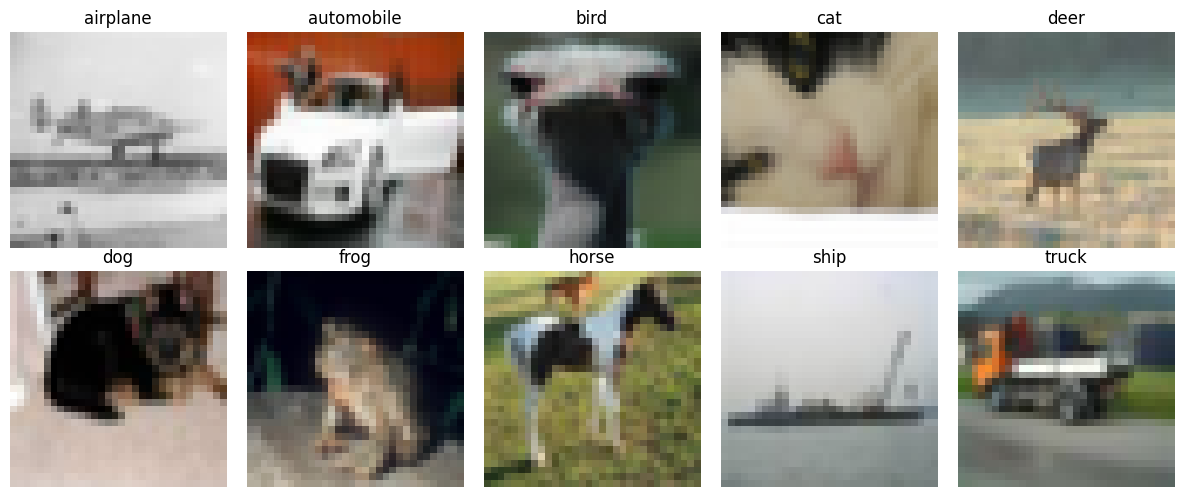

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    idx = int(torch.where(y_val == class_id)[0][0])
    ax.imshow(val_images[idx])
    ax.set_title(classes[class_id])
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'validation_examples.png', dpi=150, bbox_inches='tight')
plt.show()

# S1. Классификация CLIP и SigLIP без обучения

In [7]:
MODEL_SPECS = {
    'CLIP': ('openai/clip-vit-base-patch32', CLIPModel),
    'SigLIP': ('google/siglip-base-patch16-224', SiglipModel),
}
TEMPLATES = {
    'name': '{}',
    'photo': 'a photo of a {}.',
    'sentence': 'This is a photo of a {}.',
}

def pooled_features(output):
    if isinstance(output, torch.Tensor):
        return output
    return output.pooler_output

@torch.no_grad()
def encode_images(model, processor, images, batch_size=16):
    chunks = []
    for start in range(0, len(images), batch_size):
        inputs = processor(
            images=images[start:start + batch_size],
            return_tensors='pt',
        ).to(device)
        features = pooled_features(model.get_image_features(**inputs))
        chunks.append(F.normalize(features.float(), dim=-1).cpu())
    return torch.cat(chunks)

@torch.no_grad()
def encode_texts(model, processor, texts, kind):
    padding = 'max_length' if kind == 'SigLIP' else True
    inputs = processor(
        text=texts,
        padding=padding,
        truncation=True,
        return_tensors='pt',
    ).to(device)
    features = pooled_features(model.get_text_features(**inputs))
    return F.normalize(features.float(), dim=-1).cpu()

In [8]:
cache = {}
for kind, (model_id, model_class) in MODEL_SPECS.items():
    print('Loading', model_id)
    processor = AutoProcessor.from_pretrained(model_id)
    model = model_class.from_pretrained(model_id).to(device).eval()
    model.requires_grad_(False)
    image_val = encode_images(model, processor, val_images)
    image_test = encode_images(model, processor, test_images)
    prototypes = {
        name: encode_texts(
            model, processor, [template.format(c) for c in classes], kind
        )
        for name, template in TEMPLATES.items()
    }
    prototypes['ensemble'] = F.normalize(
        torch.stack(list(prototypes.values())).mean(dim=0), dim=-1
    )
    scale = model.logit_scale.detach().float().exp().cpu()
    bias = (
        model.logit_bias.detach().float().cpu()
        if kind == 'SigLIP'
        else torch.tensor(0.0)
    )
    texts = [TEMPLATES['photo'].format(c) for c in classes]
    inputs = processor(
        images=test_images[:2],
        text=texts,
        padding='max_length' if kind == 'SigLIP' else True,
        truncation=True,
        return_tensors='pt',
    ).to(device)
    with torch.no_grad():
        official = model(**inputs).logits_per_image.float().cpu()
    manual = scale * image_test[:2] @ prototypes['photo'].T + bias
    assert torch.allclose(official, manual, atol=2e-3, rtol=2e-3)
    assert torch.isfinite(image_test).all()
    assert torch.allclose(
        image_test.norm(dim=-1), torch.ones(len(test_images)), atol=1e-4
    )
    assert image_test.shape[1] == prototypes['photo'].shape[1]
    cache[kind] = {
        'val': image_val,
        'test': image_test,
        'texts': prototypes,
        'scale': scale,
        'bias': bias,
        'model_id': model_id,
        'revision': getattr(model.config, '_commit_hash', None),
    }
    torch.save(cache[kind], OUT / f'{kind}_features.pt')
    print(kind)
    print('image_test:', tuple(image_test.shape))
    print("prototypes['photo']:", tuple(prototypes['photo'].shape))
    print('similarities:', tuple((image_test @ prototypes['photo'].T).shape))
    print('scale:', scale.item(), 'bias:', bias.item())
    del model, processor, inputs, official
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()

Loading openai/clip-vit-base-patch32


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP
image_test: (500, 512)
prototypes['photo']: (10, 512)
similarities: (500, 10)
scale: 100.0 bias: 0.0
Loading google/siglip-base-patch16-224


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  813MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

SigLIP
image_test: (500, 768)
prototypes['photo']: (10, 768)
similarities: (500, 10)
scale: 117.33076477050781 bias: -12.9324369430542


In [9]:
def classification_metrics(features, prototypes, labels):
    pred = (features @ prototypes.T).argmax(dim=-1).numpy()
    truth = labels.numpy()
    return {
        'accuracy': accuracy_score(truth, pred),
        'macro_f1': f1_score(truth, pred, average='macro', zero_division=0),
    }

val_rows = []
for kind, item in cache.items():
    for prompt, texts in item['texts'].items():
        val_rows.append({
            'model': kind,
            'prompt': prompt,
            **classification_metrics(item['val'], texts, y_val),
        })
val_table = pd.DataFrame(val_rows)
val_table.to_csv(OUT / 'validation.csv', index=False)
display(val_table)

,model,prompt,accuracy,macro_f1
0,CLIP,name,0.855,0.853495
1,CLIP,photo,0.875,0.872278
2,CLIP,sentence,0.875,0.871722
3,CLIP,ensemble,0.875,0.873436
4,SigLIP,name,0.920,0.920926
5,SigLIP,photo,0.935,0.935493
6,SigLIP,sentence,0.920,0.919725
7,SigLIP,ensemble,0.915,0.915321


# S2. Формулировки, ансамбль описаний и уверенность

In [10]:
selected = {}
test_rows = []
prediction_rows = []
for kind, item in cache.items():
    candidates = val_table[val_table.model == kind]
    best_row = candidates.loc[candidates.accuracy.idxmax()]
    chosen = best_row['prompt']
    selected[kind] = chosen
    for prompt in dict.fromkeys(['photo', chosen]):
        texts = item['texts'][prompt]
        test_rows.append({
            'model': kind,
            'prompt': prompt,
            'selected_on_val': prompt == chosen,
            **classification_metrics(item['test'], texts, y_test),
        })
    texts = item['texts'][chosen]
    similarities = item['test'] @ texts.T
    predictions = similarities.argmax(dim=-1)
    for i, (truth, pred) in enumerate(zip(y_test.tolist(), predictions.tolist())):
        prediction_rows.append({
            'model': kind,
            'index': i,
            'true_class': classes[truth],
            'predicted_class': classes[pred],
            'similarity': similarities[i, pred].item(),
        })

test_table = pd.DataFrame(test_rows)
test_table.to_csv(OUT / 'test.csv', index=False)
pd.DataFrame(prediction_rows).to_csv(OUT / 'test_predictions.csv', index=False)
display(pd.DataFrame({'model': selected.keys(), 'selected_prompt': selected.values()}))
display(test_table)

,model,selected_prompt
0,CLIP,photo
1,SigLIP,photo


,model,prompt,selected_on_val,accuracy,macro_f1
0,CLIP,photo,True,0.906,0.904781
1,SigLIP,photo,True,0.940,0.940322


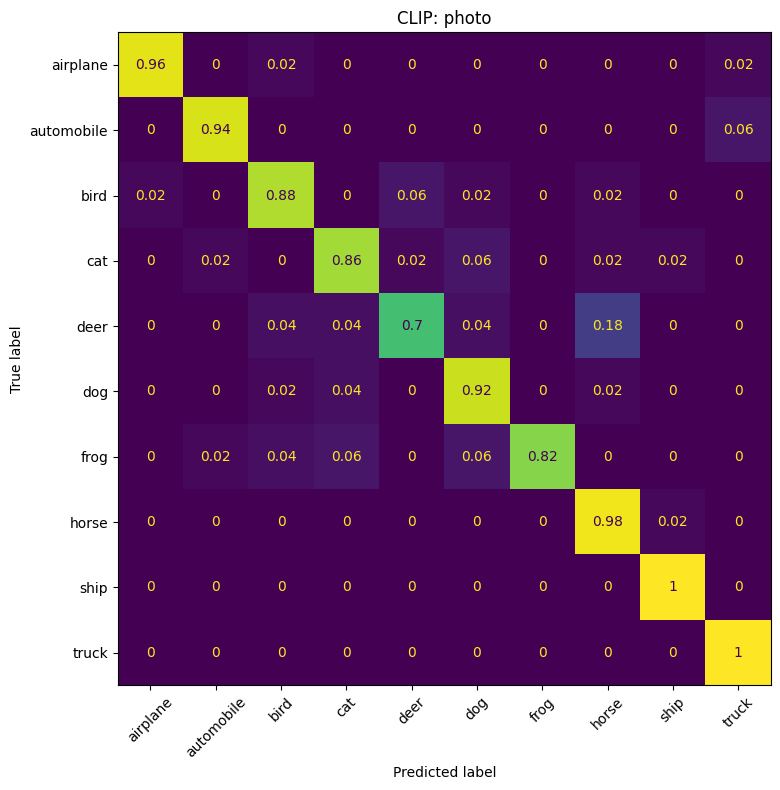

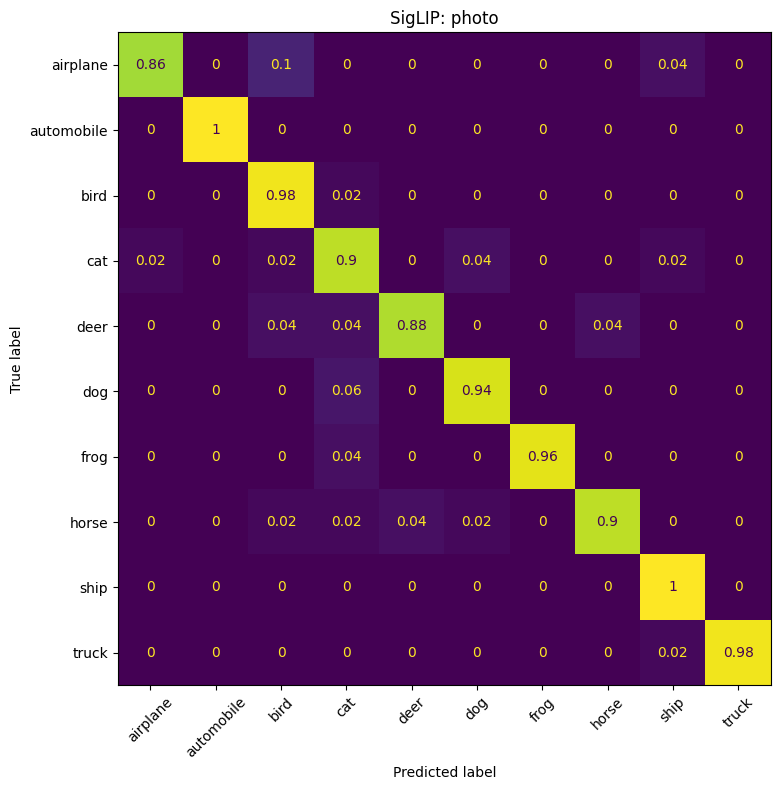

In [11]:
for kind, item in cache.items():
    texts = item['texts'][selected[kind]]
    prediction = (item['test'] @ texts.T).argmax(dim=-1).numpy()
    fig, ax = plt.subplots(figsize=(9, 8))
    ConfusionMatrixDisplay.from_predictions(
        y_test.numpy(),
        prediction,
        display_labels=classes,
        normalize='true',
        xticks_rotation=45,
        ax=ax,
        colorbar=False,
    )
    ax.set_title(f'{kind}: {selected[kind]}')
    fig.tight_layout()
    fig.savefig(OUT / f'{kind}_confusion.png', dpi=150, bbox_inches='tight')
    plt.show()

In [12]:
confidence_rows = []
for kind, item in cache.items():
    proto = item['texts']['photo']
    logits = item['scale'] * item['test'][0:1] @ proto.T + item['bias']
    small_softmax = logits[:, :3].softmax(dim=-1)
    full_softmax = logits.softmax(dim=-1)[:, :3]
    small_sigmoid = logits[:, :3].sigmoid()
    full_sigmoid = logits.sigmoid()[:, :3]
    assert torch.allclose(small_sigmoid, full_sigmoid)
    for i, class_name in enumerate(classes[:3]):
        confidence_rows.append({
            'model': kind,
            'true_class': classes[y_test[0].item()],
            'candidate': class_name,
            'softmax_3': small_softmax[0, i].item(),
            'softmax_10': full_softmax[0, i].item(),
            'sigmoid': small_sigmoid[0, i].item(),
        })
confidence_table = pd.DataFrame(confidence_rows)
confidence_table.to_csv(OUT / 'candidate_dependence.csv', index=False)
display(confidence_table)

,model,true_class,candidate,softmax_3,softmax_10,sigmoid
0,CLIP,bird,airplane,0.016311,0.000709,1.000000e+00
1,CLIP,bird,automobile,0.055870,0.002430,1.000000e+00
2,CLIP,bird,bird,0.927819,0.040358,1.000000e+00
3,SigLIP,bird,airplane,0.000184,0.000024,2.173018e-06
4,SigLIP,bird,automobile,0.000033,0.000004,3.960277e-07
5,SigLIP,bird,bird,0.999783,0.131900,1.168996e-02


# S3. Межмодальный поиск

In [13]:
def retrieval_metrics(image_features, text_features, labels, k=5):
    scores = text_features @ image_features.T
    k = min(k, image_features.shape[0])
    top = scores.topk(k, dim=-1).indices
    relevance = labels[top].eq(torch.arange(len(classes))[:, None])
    found = relevance.sum(dim=1).float()
    totals = torch.bincount(labels, minlength=len(classes)).float()
    return {
        f'precision@{k}': (found / k).mean().item(),
        f'recall@{k}': (found / totals).mean().item(),
        f'hit@{k}': relevance.any(dim=1).float().mean().item(),
    }, top, scores

retrieval_rows = []
retrieval_details = []
retrieval_cache = {}
for kind, item in cache.items():
    texts = item['texts'][selected[kind]]
    metrics, top, scores = retrieval_metrics(item['test'], texts, y_test)
    retrieval_cache[kind] = {'top': top, 'scores': scores}
    retrieval_rows.append({'model': kind, **metrics})
    for query_id, query_name in enumerate(classes):
        for rank, idx in enumerate(top[query_id].tolist(), start=1):
            retrieved_id = y_test[idx].item()
            retrieval_details.append({
                'model': kind,
                'query': query_name,
                'rank': rank,
                'image_index': idx,
                'retrieved_class': classes[retrieved_id],
                'relevant': retrieved_id == query_id,
                'score': scores[query_id, idx].item(),
            })

retrieval_table = pd.DataFrame(retrieval_rows)
retrieval_details = pd.DataFrame(retrieval_details)
retrieval_table.to_csv(OUT / 'retrieval.csv', index=False)
retrieval_details.to_csv(OUT / 'retrieval_details.csv', index=False)
display(retrieval_table)

,model,precision@5,recall@5,hit@5
0,CLIP,0.98,0.098,1.0
1,SigLIP,1.00,0.100,1.0


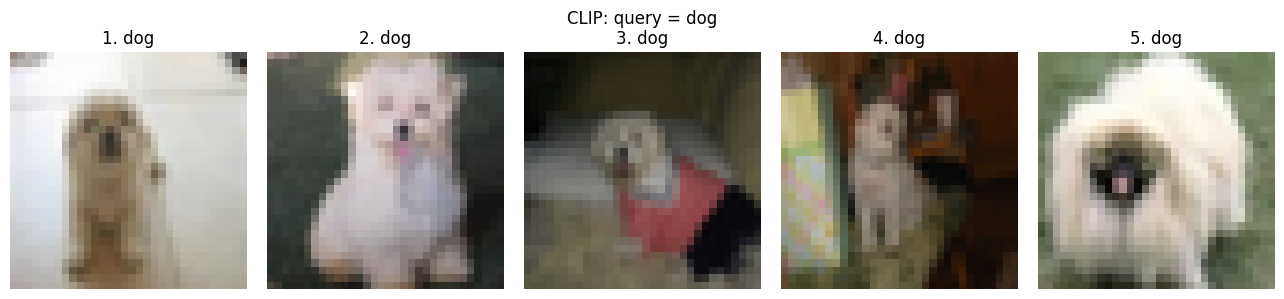

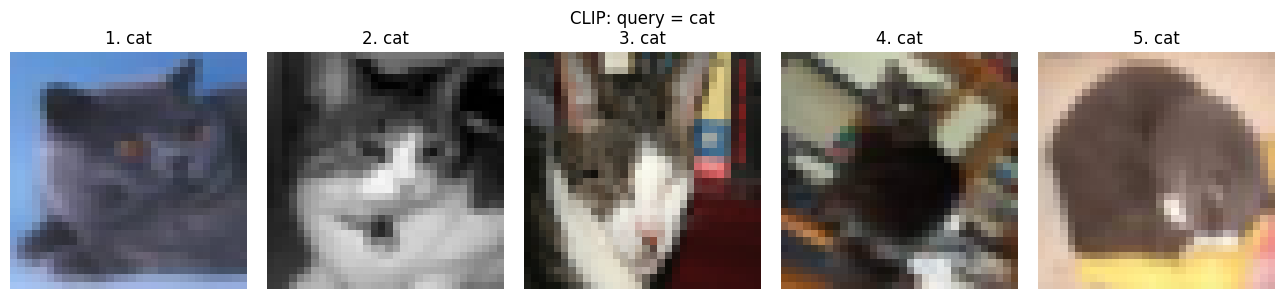

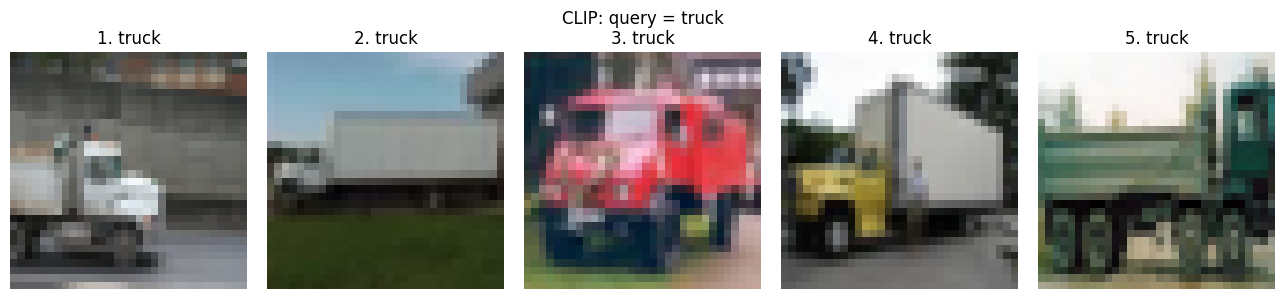

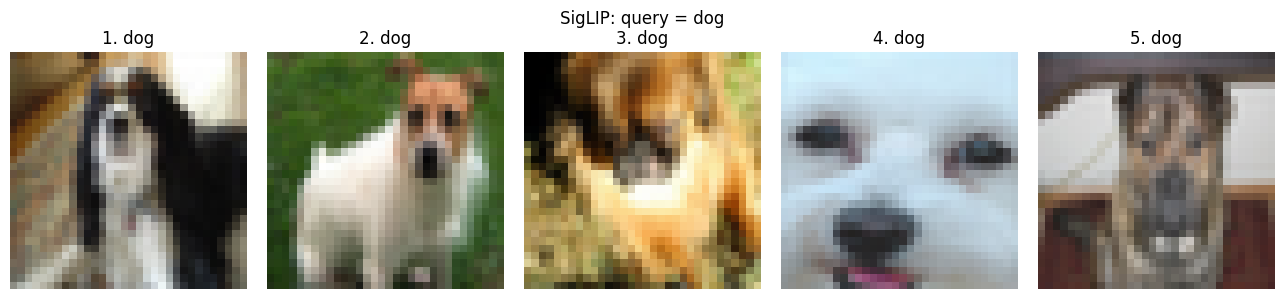

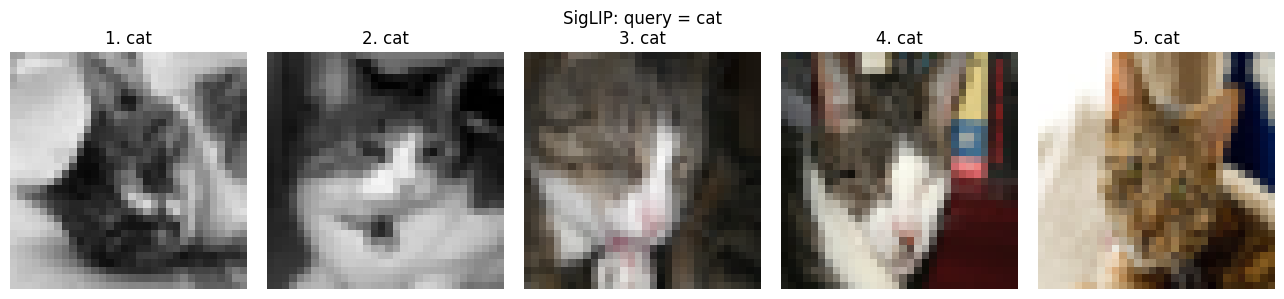

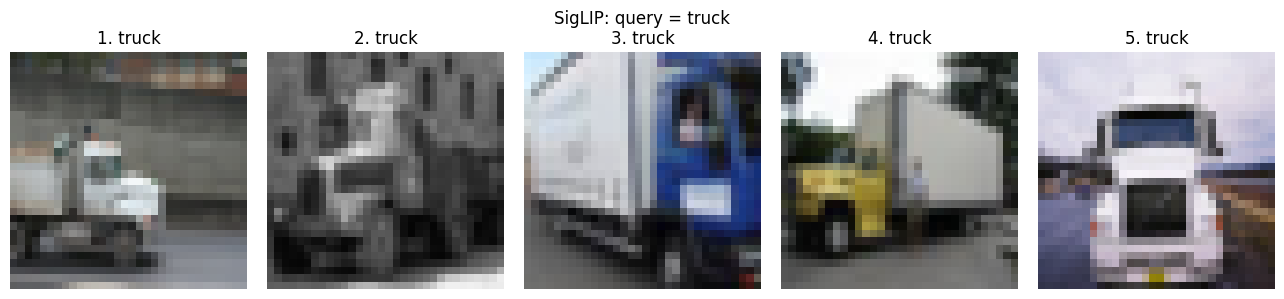

In [14]:
for kind, result in retrieval_cache.items():
    for query_name in ['dog', 'cat', 'truck']:
        query_id = classes.index(query_name)
        fig, axes = plt.subplots(1, 5, figsize=(13, 3))
        for rank, (ax, idx) in enumerate(
            zip(axes, result['top'][query_id].tolist()), start=1
        ):
            ax.imshow(test_images[idx])
            ax.set_title(f'{rank}. {classes[y_test[idx].item()]}')
            ax.axis('off')
        fig.suptitle(f'{kind}: query = {query_name}')
        fig.tight_layout()
        fig.savefig(
            OUT / f'{kind}_search_{query_name}.png',
            dpi=150,
            bbox_inches='tight',
        )
        plt.show()

,model,query,rank,image_index,retrieved_class,relevant,score
0,CLIP,horse,1,72,deer,False,0.288097


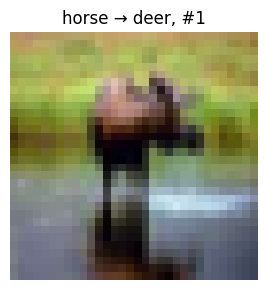

In [15]:
errors = retrieval_details[~retrieval_details.relevant].groupby(
    'model', sort=False
).head(3).reset_index(drop=True)
errors.to_csv(OUT / 'retrieval_errors.csv', index=False)
display(errors)

for kind in cache:
    model_errors = errors[errors.model == kind]
    if len(model_errors):
        fig, axes = plt.subplots(
            1, len(model_errors), figsize=(3 * len(model_errors), 3)
        )
        axes = np.atleast_1d(axes)
        for ax, row in zip(axes, model_errors.itertuples()):
            ax.imshow(test_images[row.image_index])
            ax.set_title(f'{row.query} → {row.retrieved_class}, #{row.rank}')
            ax.axis('off')
        fig.tight_layout()
        fig.savefig(
            OUT / f'{kind}_retrieval_errors.png', dpi=150, bbox_inches='tight'
        )
        plt.show()

# S4. Функции потерь: что именно меняется в обучении

In [17]:
def clip_loss(logits):
    b = logits.shape[0]
    assert logits.ndim == 2 and logits.shape[1] == b
    target = torch.arange(b, device=logits.device)
    return 0.5 * (
        F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target)
    )

def siglip_loss(logits):
    b = logits.shape[0]
    assert logits.ndim == 2 and logits.shape[1] == b
    target = torch.eye(b, device=logits.device, dtype=logits.dtype)
    return F.binary_cross_entropy_with_logits(
        logits, target, reduction='sum'
    ) / b

B = 4
zero = torch.zeros(B, B)
good = torch.full((B, B), -8.0)
good.fill_diagonal_(8.0)
bad = good[:, torch.tensor([1, 0, 3, 2])]
assert torch.allclose(clip_loss(zero), torch.tensor(math.log(B)))
assert torch.allclose(siglip_loss(zero), torch.tensor(B * math.log(2)))
assert clip_loss(good) < clip_loss(zero) < clip_loss(bad)
assert siglip_loss(good) < siglip_loss(zero) < siglip_loss(bad)
assert clip_loss(torch.zeros(1, 1)).item() == 0.0
assert torch.allclose(
    siglip_loss(torch.zeros(1, 1)), torch.tensor(math.log(2))
)
z = 2 * torch.eye(B) - 1
assert torch.allclose(
    siglip_loss(good),
    F.softplus(-z * good).sum() / B,
    atol=1e-6,
    rtol=1e-4,
)

loss_rows = []
for name, fn in [('CLIP', clip_loss), ('SigLIP', siglip_loss)]:
    for case, value in [('zero', zero), ('good', good), ('bad', bad)]:
        loss_rows.append({
            'loss': name, 'case': case, 'value': fn(value).item()
        })
loss_table = pd.DataFrame(loss_rows)
loss_table.to_csv(OUT / 'loss_checks.csv', index=False)
display(loss_table)

,loss,case,value
0,CLIP,zero,1.386294e+00
1,CLIP,good,3.576278e-07
2,CLIP,bad,1.600000e+01
3,SigLIP,zero,2.772589e+00
4,SigLIP,good,1.342486e-03
5,SigLIP,bad,1.600134e+01


In [18]:
bias = torch.tensor(-math.log(B - 1), requires_grad=True)
constant_logits = bias.expand(B, B)
loss = siglip_loss(constant_logits)
loss.backward()
assert abs(bias.grad.item()) < 1e-5

clip_logits = torch.zeros(B, B, requires_grad=True)
clip_loss(clip_logits).backward()
siglip_logits = torch.zeros(B, B, requires_grad=True)
siglip_loss(siglip_logits).backward()
off_diagonal = ~torch.eye(B, dtype=torch.bool)
assert (siglip_logits.grad.diag() < 0).all()
assert (siglip_logits.grad[off_diagonal] > 0).all()
print('optimal constant bias:', bias.item())
print('gradient:', bias.grad.item())
print('CLIP gradient at zero:')
print(clip_logits.grad)
print('SigLIP gradient at zero:')
print(siglip_logits.grad)

optimal constant bias: -1.0986123085021973
gradient: 0.0
CLIP gradient at zero:
tensor([[-0.1875,  0.0625,  0.0625,  0.0625],
        [ 0.0625, -0.1875,  0.0625,  0.0625],
        [ 0.0625,  0.0625, -0.1875,  0.0625],
        [ 0.0625,  0.0625,  0.0625, -0.1875]])
SigLIP gradient at zero:
tensor([[-0.1250,  0.1250,  0.1250,  0.1250],
        [ 0.1250, -0.1250,  0.1250,  0.1250],
        [ 0.1250,  0.1250, -0.1250,  0.1250],
        [ 0.1250,  0.1250,  0.1250, -0.1250]])


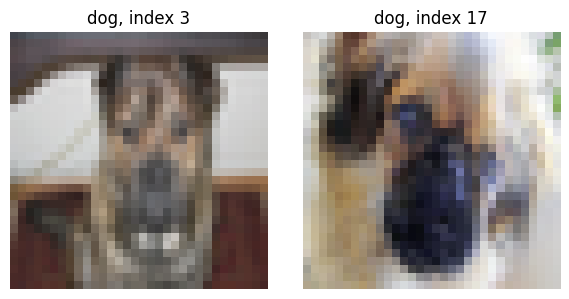

positive mask:
tensor([[1., 1., 0., 0.],
        [1., 1., 0., 0.],
        [0., 0., 1., 1.],
        [0., 0., 1., 1.]])
multi-positive loss: 2.7725887298583984
multi-positive gradient:
tensor([[-0.1250, -0.1250,  0.1250,  0.1250],
        [-0.1250, -0.1250,  0.1250,  0.1250],
        [ 0.1250,  0.1250, -0.1250, -0.1250],
        [ 0.1250,  0.1250, -0.1250, -0.1250]])


In [19]:
dog_id = classes.index('dog')
dog_indices = torch.where(y_test == dog_id)[0][:2].tolist()
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, idx in zip(axes, dog_indices):
    ax.imshow(test_images[idx])
    ax.set_title(f'dog, index {idx}')
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'false_negative_dogs.png', dpi=150, bbox_inches='tight')
plt.show()

labels_demo = torch.tensor([0, 0, 1, 1])
positive_mask = labels_demo[:, None].eq(labels_demo[None, :]).float()
logits_demo = torch.zeros(4, 4, requires_grad=True)
loss_multi = F.binary_cross_entropy_with_logits(
    logits_demo, positive_mask, reduction='sum'
) / len(labels_demo)
loss_multi.backward()
assert logits_demo.grad[0, 1] < 0
print('positive mask:')
print(positive_mask)
print('multi-positive loss:', loss_multi.item())
print('multi-positive gradient:')
print(logits_demo.grad)

In [20]:
environment = {
    'seed': SEED,
    'device': str(device),
    'python': sys.version,
    'torch': torch.__version__,
    'torchvision': __import__('torchvision').__version__,
    'transformers': transformers.__version__,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'validation_size': len(val_images),
    'test_size': len(test_images),
    'models': {
        kind: {
            'id': item['model_id'],
            'revision': item['revision'],
            'selected_prompt': selected[kind],
            'feature_dimension': item['test'].shape[1],
            'logit_scale': item['scale'].item(),
            'logit_bias': item['bias'].item(),
        }
        for kind, item in cache.items()
    },
}
(OUT / 'environment.json').write_text(
    json.dumps(environment, indent=2), encoding='utf-8'
)
print('saved to', OUT.resolve())
print(sorted(path.name for path in OUT.iterdir()))

saved to /content/results_seminar3
['CLIP_confusion.png', 'CLIP_features.pt', 'CLIP_retrieval_errors.png', 'CLIP_search_cat.png', 'CLIP_search_dog.png', 'CLIP_search_truck.png', 'SigLIP_confusion.png', 'SigLIP_features.pt', 'SigLIP_search_cat.png', 'SigLIP_search_dog.png', 'SigLIP_search_truck.png', 'candidate_dependence.csv', 'environment.json', 'false_negative_dogs.png', 'loss_checks.csv', 'retrieval.csv', 'retrieval_details.csv', 'retrieval_errors.csv', 'split.json', 'test.csv', 'test_predictions.csv', 'validation.csv', 'validation_examples.png']
